In [1]:
from google.colab import files
uploaded =files.upload()

Saving traffic.csv to traffic.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("traffic.csv")
df

,DateTime,Junction,Vehicles,ID
0,2015-11-01 00:00:00,1,15,20151101001
1,2015-11-01 01:00:00,1,13,20151101011
2,2015-11-01 02:00:00,1,10,20151101021
3,2015-11-01 03:00:00,1,7,20151101031
4,2015-11-01 04:00:00,1,9,20151101041
...,...,...,...,...
48115,2017-06-30 19:00:00,4,11,20170630194
48116,2017-06-30 20:00:00,4,30,20170630204
48117,2017-06-30 21:00:00,4,16,20170630214
48118,2017-06-30 22:00:00,4,22,20170630224


In [4]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48120 entries, 0 to 48119
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   DateTime  48120 non-null  object
 1   Junction  48120 non-null  int64 
 2   Vehicles  48120 non-null  int64 
 3   ID        48120 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB


,Junction,Vehicles,ID
count,48120.000000,48120.000000,4.812000e+04
mean,2.180549,22.791334,2.016330e+10
std,0.966955,20.750063,5.944854e+06
min,1.000000,1.000000,2.015110e+10
25%,1.000000,9.000000,2.016042e+10
50%,2.000000,15.000000,2.016093e+10
75%,3.000000,29.000000,2.017023e+10
max,4.000000,180.000000,2.017063e+10


In [5]:
print("Shape:", df.shape)
print("\nData Types:\n", df.dtypes)
print("\nMissing Values:\n", df.isnull().sum())

Shape: (48120, 4)

Data Types:
 DateTime    object
Junction     int64
Vehicles     int64
ID           int64
dtype: object

Missing Values:
 DateTime    0
Junction    0
Vehicles    0
ID          0
dtype: int64


In [6]:
df.head()
df.tail()
df.sample(5)

,DateTime,Junction,Vehicles,ID
29200,2015-11-01 16:00:00,3,4,20151101163
19687,2016-05-31 07:00:00,2,5,20160531072
311,2015-11-13 23:00:00,1,18,20151113231
7557,2016-09-10 21:00:00,1,39,20160910211
18290,2016-04-03 02:00:00,2,8,20160403022


In [7]:
df['DateTime'] = pd.to_datetime(df['DateTime'])

In [8]:
df = df.fillna(method='ffill')  # forward fill

/tmp/ipykernel_1890/4196095504.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='ffill')  # forward fill


In [9]:
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

Duplicates: 0


In [10]:
numeric_df = df[['Junction', 'Vehicles']]  # exclude ID

Q1 = numeric_df.quantile(0.25)
Q3 = numeric_df.quantile(0.75)
IQR = Q3 - Q1

outliers = ((numeric_df < (Q1 - 1.5 * IQR)) |
            (numeric_df > (Q3 + 1.5 * IQR)))

print(outliers.sum())

Junction       0
Vehicles    3617
dtype: int64


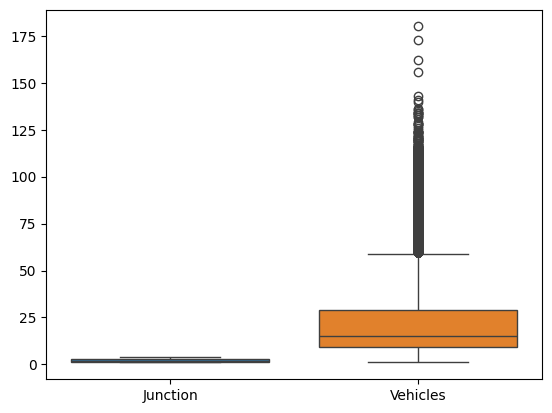

In [11]:
sns.boxplot(data=numeric_df)
plt.show()

In [12]:
df = df[~outliers.any(axis=1)]

In [13]:
# No categorical columns present

In [14]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
df[['Junction','Vehicles']] = scaler.fit_transform(df[['Junction','Vehicles']])

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df[['Junction','Vehicles']] = scaler.fit_transform(df[['Junction','Vehicles']])

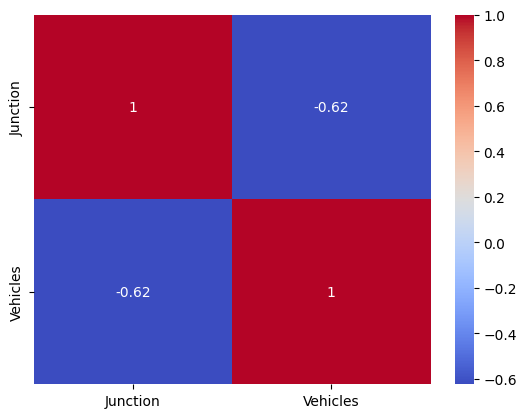

In [16]:
corr = df[['Junction','Vehicles']].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

In [17]:
df['Hour'] = df['DateTime'].dt.hour
df['Day'] = df['DateTime'].dt.day
df['Month'] = df['DateTime'].dt.month

In [18]:
df = df.replace("?", np.nan)
df = df.fillna(method='ffill')

/tmp/ipykernel_1890/1358163492.py:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='ffill')


In [19]:
from sklearn.model_selection import train_test_split

X = df[['Junction','Hour','Day','Month']]
y = df['Vehicles']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [20]:
# Not applicable for this dataset

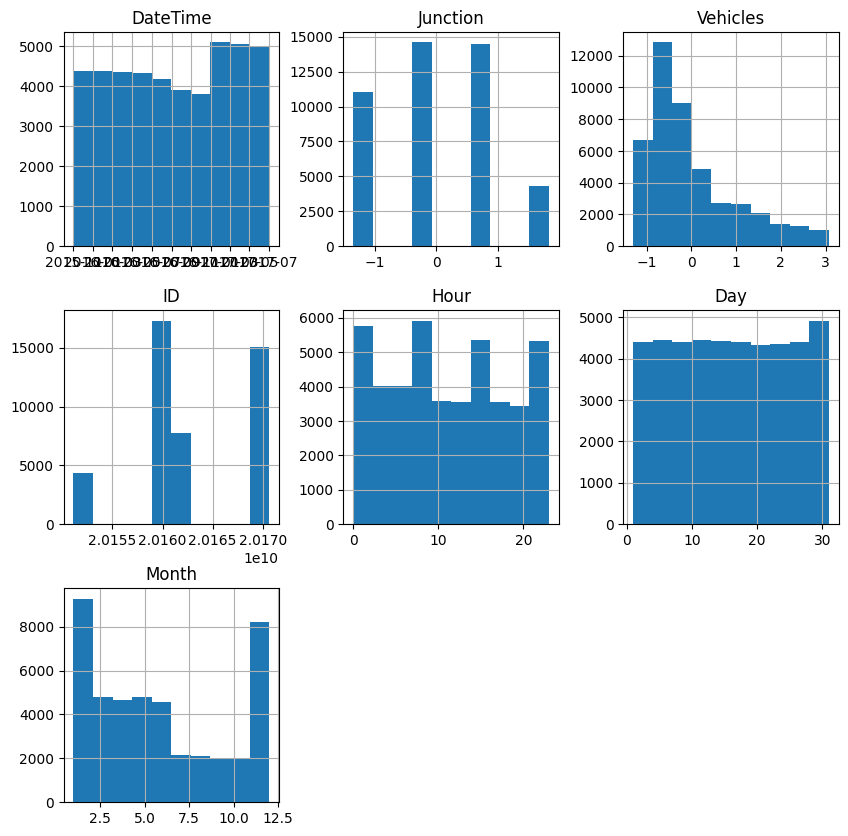

In [21]:
df.hist(figsize=(10,10))
plt.show()

In [22]:
df.to_csv("cleaned_traffic.csv", index=False)